# AA 279B - Homework 3

## Imports

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
from numpy.linalg import norm
from scipy.integrate import solve_ivp
from scipy.optimize import root_scalar, fsolve
import matplotlib.pyplot as plt
from lamberthub import vallado2013
import plotly.graph_objects as go
from scipy.interpolate import CubicSpline

import astropy.units as u
from astropy.time import Time
from astropy.coordinates import GCRS, ITRS, CartesianRepresentation

## Problem 3.1

In [3]:
# ICs
r1 = np.array([0, 0, 3])
r2 = np.array([0, -4, 0])

# 3-4-5 triangle
r1 = 3
r2 = 4
c = 5
s = (r1 + r2 + c) / 2
p_m = 2/c * (s - r1) * (s - r2)

e_m = np.sqrt(1 - 2*p_m/s)

print(f"ecc: {e_m}")


ecc: 0.44721359549995776


## Problem 3.2

In [4]:
# km3/m2
MU_EARTH = 398600.4418

# km
R_EARTH = 6378.137

# rad/s
W_EARTH = 0.0000729211585530

J2_EARTH = 1.0826267e-3

MIN_TO_SEC = 60
tof = 75 * MIN_TO_SEC

In [5]:
# ICs
r1 = np.array([-15000, 0, 0])
r2 = np.array([-2000, -11000, 0])

### Part a

In [6]:
v1,v2 = vallado2013(MU_EARTH, r1, r2, tof)
print(f"Vallado v1: {norm(v1)} km/s")

Vallado v1: 4.116082219551546 km/s


### Part b

In [7]:
def two_body(t,x,mu=MU_EARTH):
    del t
    r,v = x[0:3], x[3:6]
    a = -mu / norm(r)**3 * r
    return np.concat((v,a))

N = 1000
t_arr = np.linspace(0, tof, N)
sol: np.ndarray = solve_ivp(two_body, (0, tof), np.concatenate((r1, v1)), t_eval=t_arr, rtol=1e-6, atol=1e-9)

In [8]:
print(f"Final r value [km]: \n\t{sol.y[0:3, -1]}")
print(f"Goal r value [km]: \n\t{r2}")
err = r2-sol.y[0:3,-1]
print(f"Err [km]:\n\t{err} ({norm(err):.4f} km)")
print(f"Within {norm(err)*1000:.3f}m, so it did a good job")

Final r value [km]: 
	[ -1999.9895746  -10999.98043675      0.        ]
Goal r value [km]: 
	[ -2000 -11000      0]
Err [km]:
	[-0.0104254  -0.01956325  0.        ] (0.0222 km)
Within 22.168m, so it did a good job


In [9]:
def plot_3d(
    t_arrs,
    traces,
    labels="Orbit",
    title="3D Orbits",
    r_earth=R_EARTH,
    t_max=None
):

    fig = go.Figure()

    # Earth
    u_ = np.linspace(0, 2*np.pi, 80)
    v_ = np.linspace(0, np.pi, 40)

    x_earth = r_earth * np.outer(np.cos(u_), np.sin(v_))
    y_earth = r_earth * np.outer(np.sin(u_), np.sin(v_))
    z_earth = r_earth * np.outer(np.ones_like(u_), np.cos(v_))

    fig.add_trace(go.Surface(
        x=x_earth,
        y=y_earth,
        z=z_earth,
        name="Earth",
        showscale=False,
        opacity=0.7,
        colorscale=[[0, "royalblue"], [1, "royalblue"]]
    ))

    # Allow a single (N,3) trajectory
    if isinstance(traces, np.ndarray) and traces.ndim == 2:
        traces = [traces]

    # One time array shared by all trajectories
    if isinstance(t_arrs, np.ndarray) and t_arrs.ndim == 1:
        t_arrs = [t_arrs] * len(traces)

    if isinstance(labels, str):
        labels = [labels] * len(traces)

    for t_arr, trace, label in zip(t_arrs, traces, labels):
        t_arr = np.asarray(t_arr)
        trace = np.asarray(trace)

        if trace.ndim != 2 or trace.shape[1] != 3:
            raise ValueError(
                f"{label}: trace must have shape (N, 3), got {trace.shape}"
            )

        if len(t_arr) != len(trace):
            raise ValueError(
                f"{label}: len(t_arr)={len(t_arr)} != len(trace)={len(trace)}"
            )

        # Clip to requested maximum time
        if t_max is not None:
            mask = t_arr <= t_max
            t_arr = t_arr[mask]
            trace = trace[mask]

        if len(t_arr) < 2:
            continue

        cs = CubicSpline(t_arr, trace, axis=0)

        t_fine = np.linspace(t_arr[0], t_arr[-1], 1000)
        r_fine = cs(t_fine)

        fig.add_trace(go.Scatter3d(
            x=r_fine[:, 0],
            y=r_fine[:, 1],
            z=r_fine[:, 2],
            mode="lines",
            name=f"{label} Trajectory",
            line=dict(width=5)
        ))

        fig.add_trace(go.Scatter3d(
            x=[r_fine[-1, 0]],
            y=[r_fine[-1, 1]],
            z=[r_fine[-1, 2]],
            mode="markers",
            name=f"{label} Final position",
            marker=dict(size=6)
        ))

    fig.update_layout(
        title=title,
        scene=dict(
            xaxis_title="x [km]",
            yaxis_title="y [km]",
            zaxis_title="z [km]",
            aspectmode="data"
        ),
        template="plotly_white",
        legend=dict(x=0.02, y=0.98),
        height=900
    )

    fig.show()

In [10]:
plot_3d(sol.t, sol.y[:3,:].T, "Launcher", title="Lambert Solution")

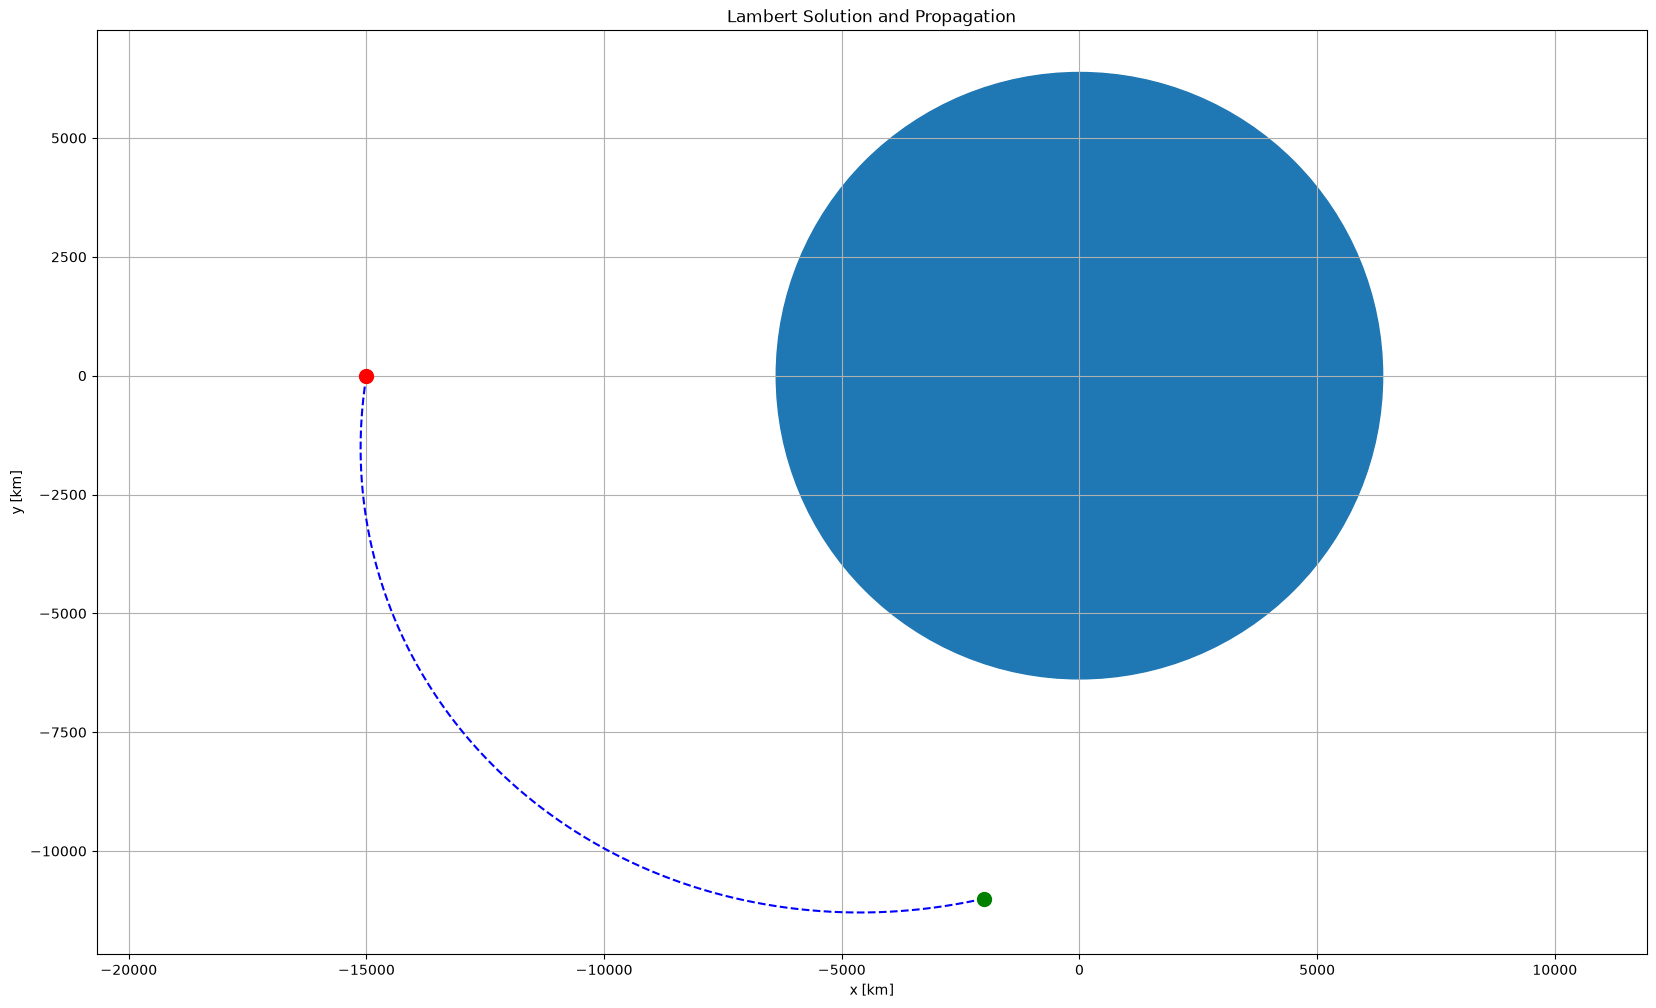

In [11]:
fig, ax = plt.subplots(figsize=(20, 12))
ax.set_title('Lambert Solution and Propagation')

# Trajectory
ax.plot(sol.y[0], sol.y[1], 'b--', label='Trajectory')

# Points
ax.plot(r1[0], r1[1], 'ro', markersize=10, label='r1')
ax.plot(r2[0], r2[1], 'go', markersize=10, label='r2')

# Body
ax.add_patch(plt.Circle((0,0), R_EARTH, color='tab:blue', fill=True))


ax.set_xlabel('x [km]')
ax.set_ylabel('y [km]')
ax.set_aspect('equal', adjustable='datalim')

ax.grid(True)
plt.show()

### Part c

In [12]:
def two_body_with_J2(t,x,mu=MU_EARTH, j2=J2_EARTH):
    state_dot = two_body(t,x,mu)
    
    norm_r = norm(x[0:3])
    r_hat = x[0:3] / norm_r
    k_hat = np.array([0,0,1])
    z = x[2]
    
    a_J2 = -(mu*j2*R_EARTH*R_EARTH/2) * (
        6*z/norm_r**5 * k_hat +
        (3/norm_r**4 - 15*z*z/norm_r**6) * r_hat
    )
    state_dot[3:6] += a_J2
    return state_dot


sol_J2: np.ndarray = solve_ivp(two_body_with_J2, (0, tof), np.concatenate((r1, v1)), method='LSODA', t_eval=t_arr, rtol=1e-6, atol=1e-9)

In [13]:
print(f"Final r value [km]: \n\t{sol_J2.y[0:3, -1]}")
print(f"Goal r value [km]: \n\t{r2}")

err = r2-sol_J2.y[0:3,-1]
print(f"Err [km]:\n\t{err} ({norm(err):.4f} km)")
print("Not particularly well compared to Lambert")

Final r value [km]: 
	[ -1994.11058014 -10995.388839        0.        ]
Goal r value [km]: 
	[ -2000 -11000      0]
Err [km]:
	[-5.88941986 -4.611161    0.        ] (7.4798 km)
Not particularly well compared to Lambert


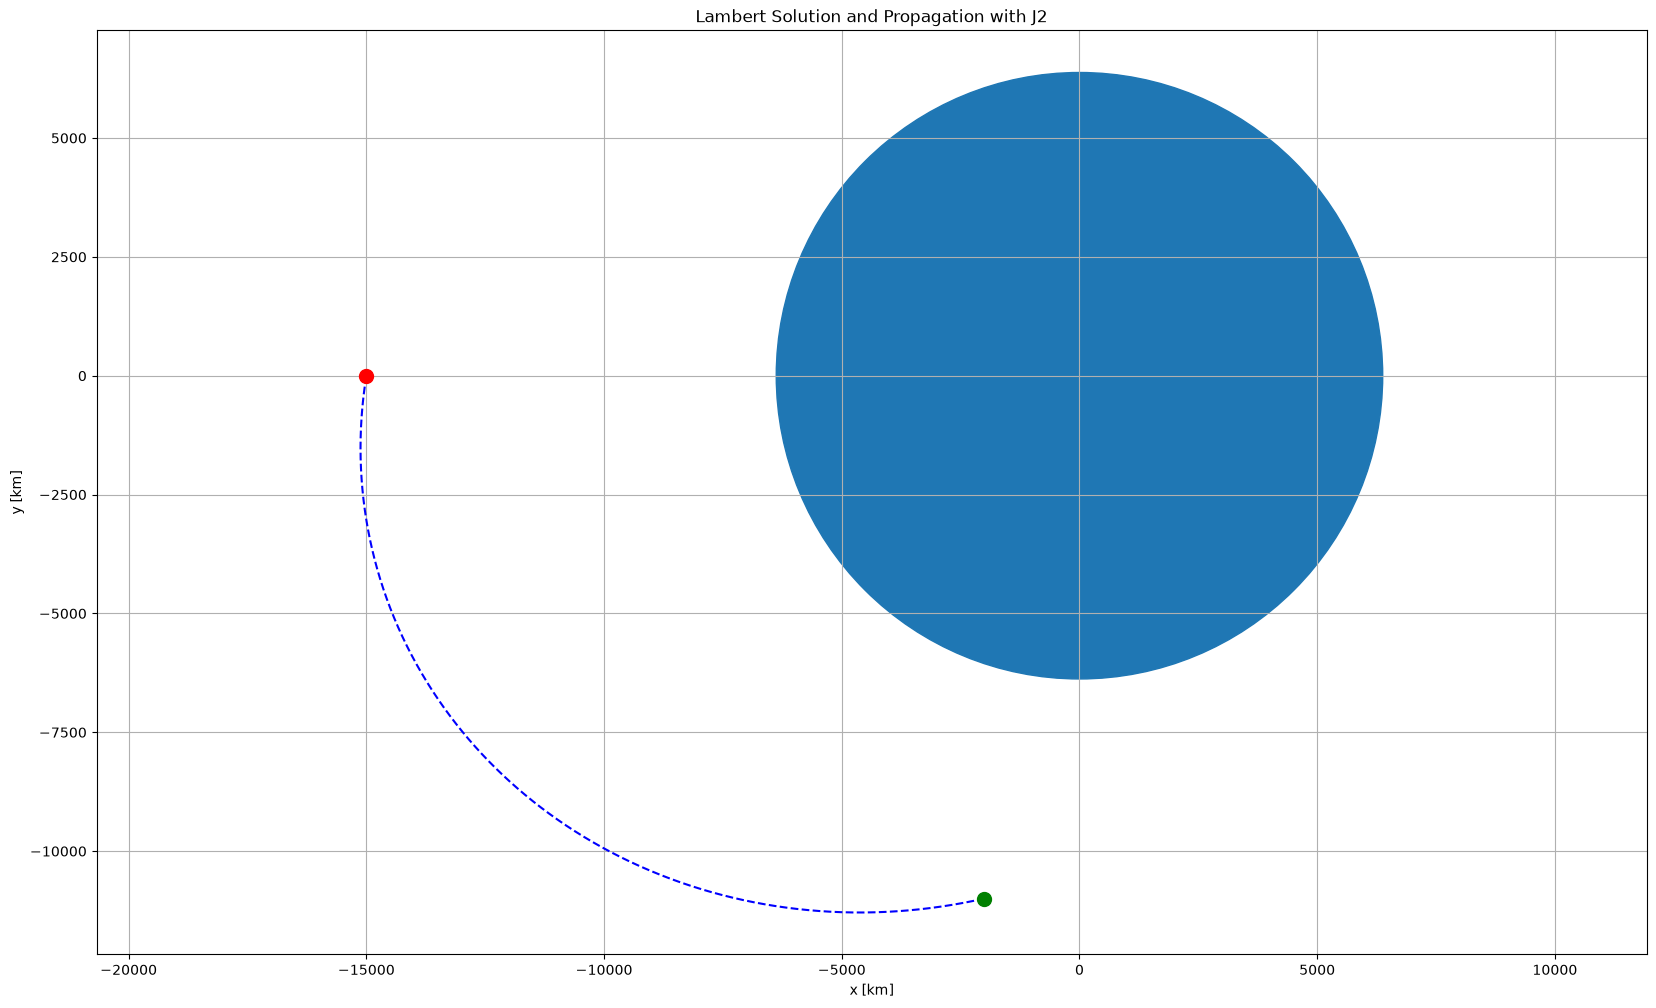

In [14]:
fig, ax = plt.subplots(figsize=(20, 12))
ax.set_title('Lambert Solution and Propagation with J2')

# Trajectory
ax.plot(sol_J2.y[0], sol_J2.y[1], 'b--', label='Trajectory')

# Points
ax.plot(r1[0], r1[1], 'ro', markersize=10, label='r1')
ax.plot(r2[0], r2[1], 'go', markersize=10, label='r2')

# Body
ax.add_patch(plt.Circle((0,0), R_EARTH, color='tab:blue', fill=True))


ax.set_xlabel('x [km]')
ax.set_ylabel('y [km]')
ax.set_aspect('equal', adjustable='datalim')

ax.grid(True)
plt.show()

### Part d

In [15]:
def AA279jacobianshoot(odefun, tspan, y0in, dv, t_arr):
    """
    Returns 3x3 Jacobian for shooting method

    AA279 Function Library
    Last modified: 7 October 2026 by Andrew K. Barrows

    Jacobian describes sensitivity of final position to initial velocity

    State must be of the form [rx ry rz vx vy vz]'

    sample function call:
    J = jacobianshoot(@earthorbitbody, [0; 75*60], [r1; v1], 0.001)

    odefun function handle for state derivative function
    tspan trajectory start and end times [sec]
    y0in state at which J should be evaluated
    dv small velocity increment used for finite differences
    t_arr array to be evaluated at
    
    """

    J = np.zeros((3,3))
    y0in = np.asarray(y0in)

    # vx
    y0 = y0in + [0,0,0,dv,0,0]
    sol = solve_ivp(odefun, (t_arr[0], t_arr[-1]), y0, method='LSODA', t_eval=t_arr, rtol=1e-6, atol=1e-9)
    rhigh = sol.y[0:3, -1]
    y0 = y0in + [0,0,0,-dv,0,0]
    sol = solve_ivp(odefun, (t_arr[0], t_arr[-1]), y0, method='LSODA', t_eval=t_arr, rtol=1e-6, atol=1e-9)
    rlow = sol.y[0:3, -1]
    J[:, 0] = (rhigh-rlow)/(2*dv)

    # vx
    y0 = y0in + [0,0,0,0,dv,0]
    sol = solve_ivp(odefun, (t_arr[0], t_arr[-1]), y0, method='LSODA', t_eval=t_arr, rtol=1e-6, atol=1e-9)
    rhigh = sol.y[0:3, -1]
    y0 = y0in + [0,0,0,0,-dv,0]
    sol = solve_ivp(odefun, (t_arr[0], t_arr[-1]), y0, method='LSODA', t_eval=t_arr, rtol=1e-6, atol=1e-9)
    rlow = sol.y[0:3, -1]
    J[:, 1] = (rhigh-rlow)/(2*dv)

    # vx
    y0 = y0in + [0,0,0,0,0,dv]
    sol = solve_ivp(odefun, (t_arr[0], t_arr[-1]), y0, method='LSODA', t_eval=t_arr, rtol=1e-6, atol=1e-9)
    rhigh = sol.y[0:3, -1]
    y0 = y0in + [0,0,0,0,0,-dv]
    sol = solve_ivp(odefun, (t_arr[0], t_arr[-1]), y0, method='LSODA', t_eval=t_arr, rtol=1e-6, atol=1e-9)
    rlow = sol.y[0:3, -1]
    J[:, 2] = (rhigh-rlow)/(2*dv)

    return J

In [16]:
def find_initial_conditions(t_arr, ode, state0, r_goal, iter = 10, convergence_bound = 10e-5, verbose = False):
    """10 cm bound"""

    
    tof = t_arr[-1]
    
    state = state0
    
    for i in range(iter):
        sim = solve_ivp(ode, (0, tof), state, method='LSODA', t_eval=t_arr, rtol=1e-6, atol=1e-9).y
        
        dr = sim[0:3,-1] - r_goal
        dr_norm = norm(dr)
        
        if verbose:
            print(f"dr: {dr_norm:.5f}km")
        
        if norm(dr) < convergence_bound:
            print(f"\nConverged in {i} iterations with:\n\tdr = {dr_norm:.5e} km")
            break
        
        J = AA279jacobianshoot(ode, (0, tof), state, dv=0.001, t_arr=t_arr)
        
        # Only adjusting velocity
        state[3:6] -= np.linalg.pinv(J) @ dr

    return state

state0_one_update = find_initial_conditions(t_arr, two_body_with_J2, np.concatenate((r1, v1)), r2, 1)
v1_one_update = state0_one_update[3:6]

In [17]:
print(f"Old v1 value [km/s]: \n\t{v1} ({norm(v1):.3f} km/s)")
print(f"Final v1 value [km/s]: \n\t{v1_one_update} ({norm(v1_one_update):.3f} km/s)")
# print(f"Difference [km/s]:\n\t{v1-v1_one_update}")
print()
diff_m = (v1-v1_one_update)*1000
print(f"Err [m/s]:\n\t{diff_m} ({norm(diff_m):.4f} m/s)")
print("Very small difference between original and 1 iteration")

Old v1 value [km/s]: 
	[-0.65513692 -4.06361027  0.        ] (4.116 km/s)
Final v1 value [km/s]: 
	[-6.55880979e-01 -4.06399725e+00  5.80741636e-31] (4.117 km/s)

Err [m/s]:
	[ 7.44054505e-01  3.86975119e-01 -5.80741636e-28] (0.8387 m/s)
Very small difference between original and 1 iteration


### Part e

In [18]:
sol_one_update: np.ndarray = solve_ivp(two_body_with_J2, (0, tof), state0_one_update, method='LSODA', t_eval=t_arr, rtol=1e-6, atol=1e-9).y

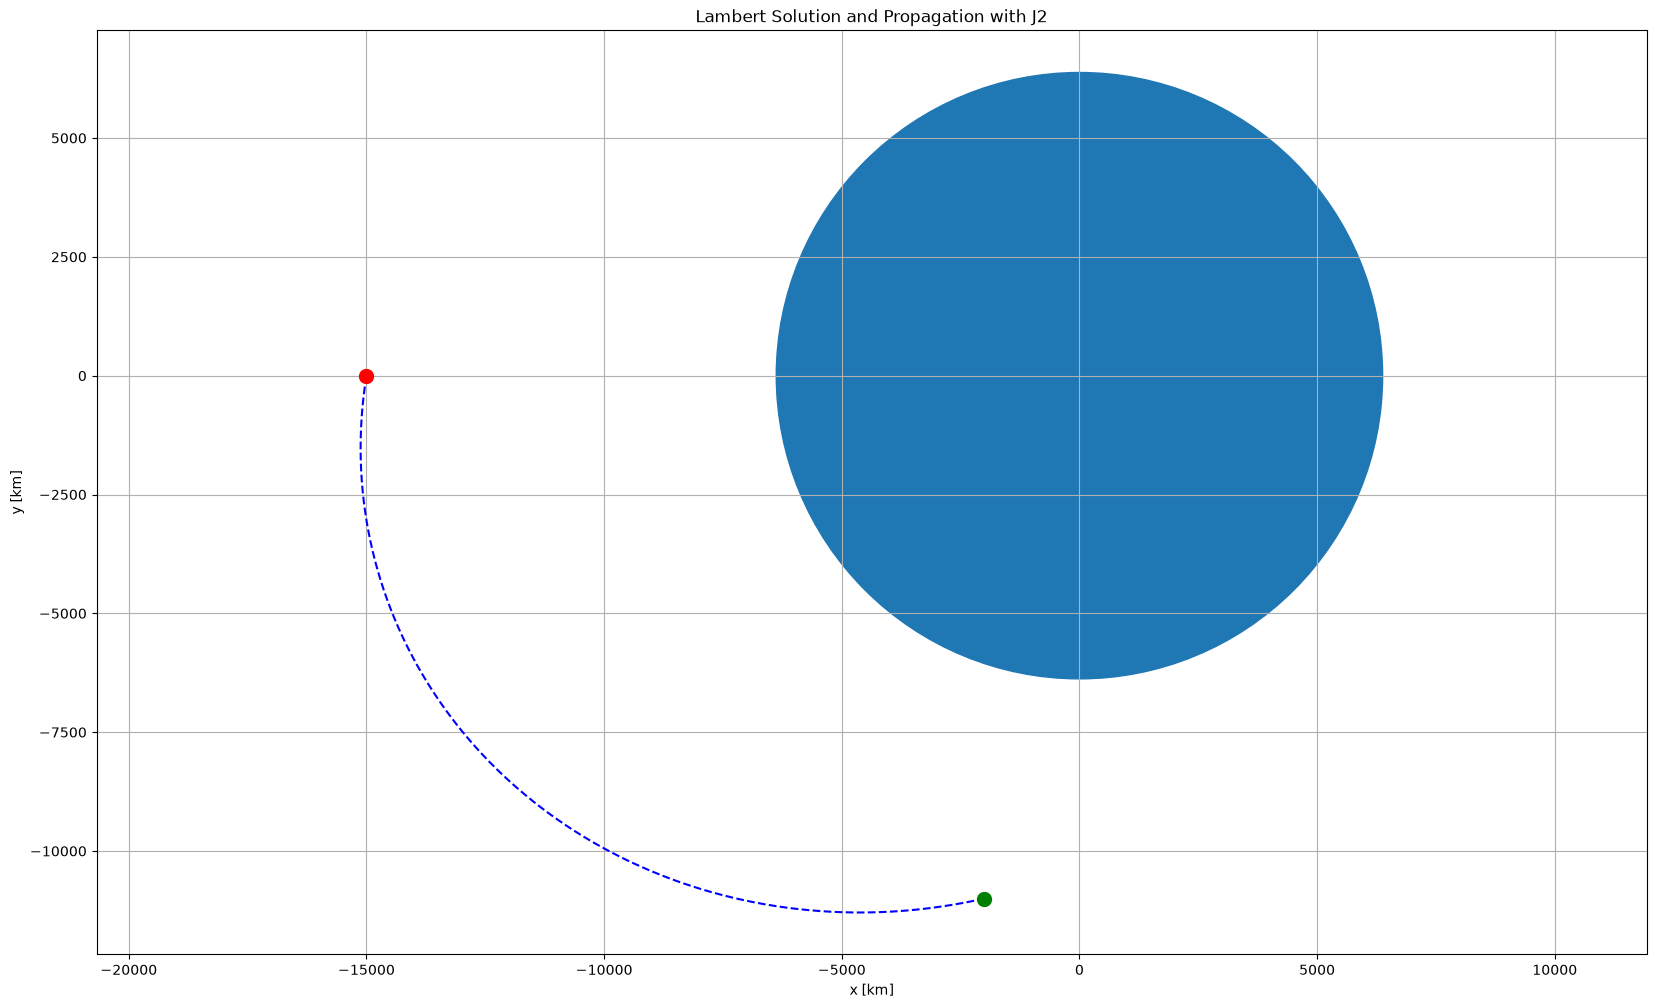

In [19]:
fig, ax = plt.subplots(figsize=(20, 12))
ax.set_title('Lambert Solution and Propagation with J2')

# Trajectory
ax.plot(sol_one_update[0], sol_one_update[1], 'b--', label='Trajectory')

# Points
ax.plot(r1[0], r1[1], 'ro', markersize=10, label='r1')
ax.plot(r2[0], r2[1], 'go', markersize=10, label='r2')

# Body
ax.add_patch(plt.Circle((0,0), R_EARTH, color='tab:blue', fill=True))


ax.set_xlabel('x [km]')
ax.set_ylabel('y [km]')
ax.set_aspect('equal', adjustable='datalim')

ax.grid(True)
plt.show()

### Part f

In [20]:
state0_full_updated = find_initial_conditions(t_arr, two_body_with_J2, np.concatenate((r1, v1)), r2)
v1_full_updated = state0_full_updated[3:6]


Converged in 3 iterations with:
	dr = 8.98310e-11 km


In [21]:
print(f"One-step v1 value [km/s]: \n\t{v1_one_update} ({norm(v1_one_update):.8f} km/s)")
print(f"Final Updated v1 value [km/s]: \n\t{v1_full_updated} ({norm(v1_full_updated):.8f} km/s)")
print()
print(f"Difference [km/s]:\n\t{v1_one_update-v1_full_updated}, ({norm(v1_one_update-v1_full_updated):.3e} km/s)")

One-step v1 value [km/s]: 
	[-6.55880979e-01 -4.06399725e+00  5.80741636e-31] (4.11658274 km/s)
Final Updated v1 value [km/s]: 
	[-6.55880936e-01 -4.06399751e+00  5.40032976e-34] (4.11658300 km/s)

Difference [km/s]:
	[-4.34170663e-08  2.62738334e-07  5.80201603e-31], (2.663e-07 km/s)
